Q1 . Equilibrium conversion checker
In a reactor the reaction A + B = C reaches equilibrium. Initial concentrations are  [A]₀ = 1.5, [B]₀ = 1.0, and [C]₀ = 0 mol/L. If x mol/L of C is formed, Kc = x/((1.5-x)(1-x)), which rearranges to the quadratic equation 
Kc*x^2 - (2.5Kc + 1)x + 1.5Kc = 0.
Write a python program that:

(a) reads Kc using input(), prints the data type of the raw input and of the converted value, and shows a clear message (no crash) if the text is not a number or if Kc <= 0;

(b) finds a,b,c, the discriminant and both roots;

(c) selects the physically meaningful root (0 <= x <= 1, because B is limiting);

(d) prints equilibrium [A],[B],[C] (3 decimals ) and the conversion of the limiting reactant B = x/[B]₀ * 100%;

(e) classifies the coversion using if /elif / else: >= 70% "High" , >= 40% "Moderate", otherwise "Low".

Test with Kc = 4 and Kc = 0.5, Kc = abc and Kc = -2.

In [2]:
import math

raw_input_value = input("Enter Kc: ")
print("Raw input:", raw_input_value)
print("Raw input type:", type(raw_input_value))

try:
    Kc = float(raw_input_value)
except ValueError:
    print("Error: Kc must be a number.")
else:
    print("Converted Kc:", Kc)
    print("Converted value type:", type(Kc))

    if not math.isfinite(Kc) or Kc <= 0:
        print("Error: Kc must be a finite number greater than 0.")
    else:
        a = Kc
        b = -(2.5 * Kc + 1)
        c = 1.5 * Kc

        discriminant = b**2 - 4 * a * c
        sqrt_discriminant = math.sqrt(discriminant)
        root1 = (-b + sqrt_discriminant) / (2 * a)
        root2 = (-b - sqrt_discriminant) / (2 * a)

        print(f"a = {a}, b = {b}, c = {c}")
        print("Discriminant:", discriminant)
        print("Root 1:", root1)
        print("Root 2:", root2)

        physical_roots = [root for root in (root1, root2) if 0 <= root <= 1]
        if not physical_roots:
            print("Error: no physically meaningful root was found.")
        else:
            x = physical_roots[0]
            equilibrium_A = 1.5 - x
            equilibrium_B = 1.0 - x
            equilibrium_C = x
            conversion_B = x / 1.0 * 100

            print(f"Equilibrium [A] = {equilibrium_A:.3f} mol/L")
            print(f"Equilibrium [B] = {equilibrium_B:.3f} mol/L")
            print(f"Equilibrium [C] = {equilibrium_C:.3f} mol/L")
            print(f"Conversion of limiting reactant B = {conversion_B:.3f}%")

            if conversion_B >= 70:
                classification = "High"
            elif conversion_B >= 40:
                classification = "Moderate"
            else:
                classification = "Low"

            print("Conversion classification:", classification)

Raw input: 4
Raw input type: <class 'str'>
Converted Kc: 4.0
Converted value type: <class 'float'>
a = 4.0, b = -11.0, c = 6.0
Discriminant: 25.0
Root 1: 2.0
Root 2: 0.75
Equilibrium [A] = 0.750 mol/L
Equilibrium [B] = 0.250 mol/L
Equilibrium [C] = 0.750 mol/L
Conversion of limiting reactant B = 75.000%
Conversion classification: High


Q2 . Batch reactor simulation and batch tracking

Part A. In a batch reactor, reactant A is consumed by a first-order reaction , dC/dT = -kC .Use the Euler method: C_old - k*C_old*delta t. Take Co = 2.5 mol/L, k=0,04 min^-1 , delta t = 1min. 

(i) Using a for loop , simulate 12 minutes and print a table of Time (min) , Concentration (mol/L) and Conversion (%).

(ii) Using math.exp() , Calculate the exact calue Coe^(-kt) at 12 min and print the absolute error of the Euler result.

(iii) Using a while loop, repeat the simulation untill conversion reaches 40% or time reaches 100min . Print the time needed and the final concentration.

Part B . Distillation-column sample codes such as DIST2026X9Q3 are stored as text. Write a program that reads a code, loops through each character , and prints the number of digits and the sum of the digits . Show a message for an empty code and for a code with no digits . Test with DIST2026X9Q3 ,an empty code and ABCDEF.

In [3]:
import math

# Part A: Euler simulation for first-order consumption of A
initial_concentration = 2.5
rate_constant = 0.04
time_step = 1.0

current_concentration = initial_concentration
current_time = 0

print("Time (min)\tConcentration (mol/L)\tConversion (%)")
print(f"{current_time}\t\t{current_concentration:.3f}\t\t\t0.000")

for step in range(1, 13):
    current_concentration = current_concentration - rate_constant * current_concentration * time_step
    current_time += time_step
    conversion = (initial_concentration - current_concentration) / initial_concentration * 100
    print(f"{current_time:.0f}\t\t{current_concentration:.3f}\t\t\t{conversion:.3f}")

exact_concentration = initial_concentration * math.exp(-rate_constant * 12)
absolute_error = abs(current_concentration - exact_concentration)
print(f"Exact concentration at 12 min = {exact_concentration:.6f} mol/L")
print(f"Absolute error at 12 min = {absolute_error:.6f} mol/L")

# Repeat Euler simulation until conversion reaches 40% or time reaches 100 min
stopping_time = 0
stopping_concentration = initial_concentration
stopping_conversion = 0.0

while stopping_conversion < 40 and stopping_time < 100:
    stopping_concentration = stopping_concentration - rate_constant * stopping_concentration * time_step
    stopping_time += time_step
    stopping_conversion = (initial_concentration - stopping_concentration) / initial_concentration * 100

print(f"Time to reach 40% conversion (1-min steps) = {stopping_time:.0f} min")
print(f"Final concentration = {stopping_concentration:.3f} mol/L")
print(f"Final conversion = {stopping_conversion:.3f}%")

# Part B: Count and sum the digits in a sample code
sample_code = input("Enter distillation-column sample code: ")
digit_count = 0
digit_sum = 0

if sample_code == "":
    print("Empty code entered.")
else:
    for character in sample_code:
        if character.isdigit():
            digit_count += 1
            digit_sum += int(character)

    if digit_count == 0:
        print("No digits found in the code.")

print("Number of digits:", digit_count)
print("Sum of digits:", digit_sum)

Time (min)	Concentration (mol/L)	Conversion (%)
0		2.500			0.000
1		2.400			4.000
2		2.304			7.840
3		2.212			11.526
4		2.123			15.065
5		2.038			18.463
6		1.957			21.724
7		1.879			24.855
8		1.803			27.861
9		1.731			30.747
10		1.662			33.517
11		1.596			36.176
12		1.532			38.729
Exact concentration at 12 min = 1.546958 mol/L
Absolute error at 12 min = 0.015184 mol/L
Time to reach 40% conversion (1-min steps) = 13 min
Final concentration = 1.471 mol/L
Final conversion = 41.180%
Number of digits: 6
Sum of digits: 22


Q3 . Solvent screening and sampling schedule

Part A. A laboratory has n candidate solvents and wants to test r of them together in a mixed solvent(order does not matter) . Write a recursive function factorial (n) (remember the base case for 0!) and a function combination(n,r) = n!/(r!(n-r)!) that uses it. Reject invalid input (negative values, r>n) . Print the number of possible mixture for n = 9, r = 3, and show the message for n = 6, r = 8.

Part B. During a crystallisation run, samples are taken at times = Fibonacci number * 4 min . Write an iterative fib_iter(n) that returns a list of first n Fibonacci numbers, and a recursive function fib_rec(k) that returns the k-th Fibonacci number (Fo = 0, F1 = 1 ). For n = 10, check that both functions agree and print a table: Sample No.| Fibonacci tag | Sampling time (min).

In [4]:
def factorial(n):
    if not isinstance(n, int) or isinstance(n, bool) or n < 0:
        raise ValueError("n must be a non-negative integer.")
    if n == 0:
        return 1
    return n * factorial(n - 1)


def combination(n, r):
    if not isinstance(n, int) or isinstance(n, bool):
        raise ValueError("n and r must be non-negative integers with r <= n.")
    if not isinstance(r, int) or isinstance(r, bool):
        raise ValueError("n and r must be non-negative integers with r <= n.")
    if n < 0 or r < 0 or r > n:
        raise ValueError("n and r must be non-negative, and r must not exceed n.")
    return factorial(n) // (factorial(r) * factorial(n - r))


print("Number of mixtures for n=9, r=3:", combination(9, 3))

try:
    combination(6, 8)
except ValueError as error:
    print("Invalid combination:", error)


def fib_iter(n):
    if not isinstance(n, int) or isinstance(n, bool) or n < 0:
        raise ValueError("n must be a non-negative integer.")
    fibonacci_numbers = []
    previous, current = 0, 1
    for _ in range(n):
        fibonacci_numbers.append(previous)
        previous, current = current, previous + current
    return fibonacci_numbers


def fib_rec(k):
    if not isinstance(k, int) or isinstance(k, bool) or k < 0:
        raise ValueError("k must be a non-negative integer.")
    if k == 0:
        return 0
    if k == 1:
        return 1
    return fib_rec(k - 1) + fib_rec(k - 2)


n = 10
fibonacci_tags = fib_iter(n)
recursive_tags = [fib_rec(index) for index in range(n)]
print("Iterative and recursive Fibonacci results agree:", fibonacci_tags == recursive_tags)
print("Sample No.\tFibonacci tag\tSampling time (min)")
for sample_number, fibonacci_tag in enumerate(fibonacci_tags, start=1):
    print(f"{sample_number}\t\tF{sample_number - 1} = {fibonacci_tag}\t\t{fibonacci_tag * 4}")

Number of mixtures for n=9, r=3: 84
Invalid combination: n and r must be non-negative, and r must not exceed n.
Iterative and recursive Fibonacci results agree: True
Sample No.	Fibonacci tag	Sampling time (min)
1		F0 = 0		0
2		F1 = 1		4
3		F2 = 1		4
4		F3 = 2		8
5		F4 = 3		12
6		F5 = 5		20
7		F6 = 8		32
8		F7 = 13		52
9		F8 = 21		84
10		F9 = 34		136


Q4 . Kinetics and gas data : pandas and matplotlib

Consumption of a reactant was studied in a batch reactor with two feed concentrations of catalyst. The concentration (mol/L) was recorded:

| Time_min | Run1_mol_L (low catalyst) | Run2_mol_L (high catalyst) |
|---:|:---:|---:|
| 0 | 1.50 | 1.50 | 
| 10 | 1.17 | 0.96 |
| 20 | 0.91 | 0.61 |
| 30 | 0.71 | 0.39 |
| 40 | 0.55 | 0.25 |
| 50 | 0.43 | 0.16 |

(a) Create a DataFrame from this table. Save it as kinetics.csv (without the index column) and as kinetics.json. Read the CSV back and print its shape and data types.

(b) Print the mean and standard deviation of Run1 and Run2, and state which run shows more variation.

(c) Plot both runs on one graph(Time on x-axis) with title, axis labels with units, legend and grid.

(d) Ethylene gas is compressed slowly in a piston-cylinder at constant temperature:

| Volume_L | 1 | 2 | 3 | 4 | 5 |
|---:|:---:|:---:|:---:|:---:|:---:|
| Pressure_bar | 5.03 | 2.52 | 1.65 | 1.26 | 1.01 |

Plot pressure vs volume as a scatter plot. Calculate k as the mean of P*V and draw the reference curve P = k/V on the same graph. Add title, lables with units and legend.

CSV shape: (6, 3)
CSV data types:
Time_min        int64
Run1_mol_L    float64
Run2_mol_L    float64
dtype: object
Run 1 mean = 0.878 mol/L; standard deviation = 0.402 mol/L
Run 2 mean = 0.645 mol/L; standard deviation = 0.507 mol/L
Run 2 shows more variation.


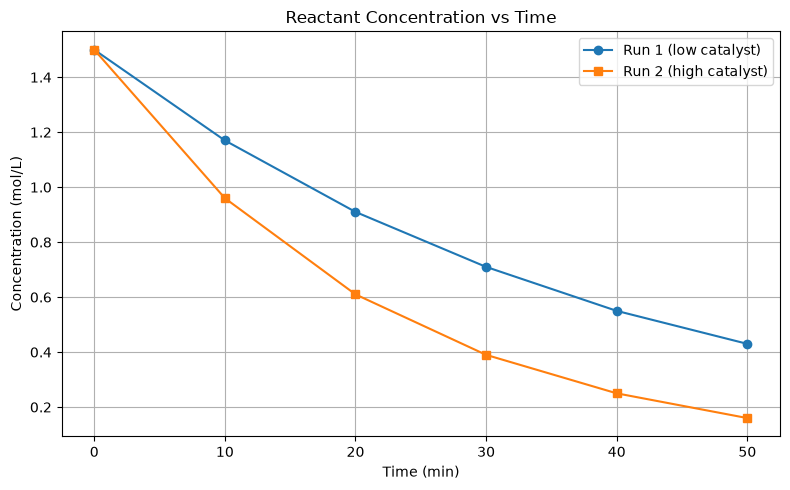

Mean P*V, k = 5.022 bar L


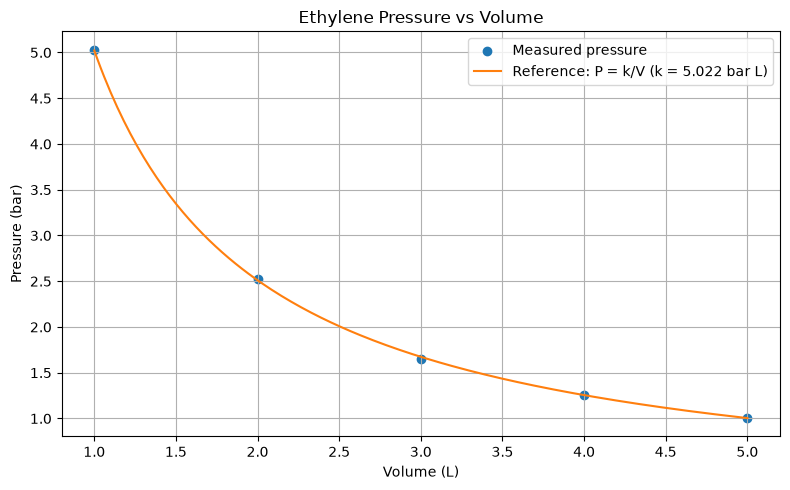

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Part A: Kinetics data, file export, and summary statistics
kinetics_data = pd.DataFrame({
    "Time_min": [0, 10, 20, 30, 40, 50],
    "Run1_mol_L": [1.50, 1.17, 0.91, 0.71, 0.55, 0.43],
    "Run2_mol_L": [1.50, 0.96, 0.61, 0.39, 0.25, 0.16],
})

kinetics_data.to_csv("kinetics.csv", index=False)
kinetics_data.to_json("kinetics.json", orient="records", indent=2)

kinetics_from_csv = pd.read_csv("kinetics.csv")
print("CSV shape:", kinetics_from_csv.shape)
print("CSV data types:")
print(kinetics_from_csv.dtypes)

run1_mean = kinetics_from_csv["Run1_mol_L"].mean()
run1_std = kinetics_from_csv["Run1_mol_L"].std()
run2_mean = kinetics_from_csv["Run2_mol_L"].mean()
run2_std = kinetics_from_csv["Run2_mol_L"].std()

print(f"Run 1 mean = {run1_mean:.3f} mol/L; standard deviation = {run1_std:.3f} mol/L")
print(f"Run 2 mean = {run2_mean:.3f} mol/L; standard deviation = {run2_std:.3f} mol/L")
if run1_std > run2_std:
    print("Run 1 shows more variation.")
else:
    print("Run 2 shows more variation.")

plt.figure(figsize=(8, 5))
plt.plot(kinetics_from_csv["Time_min"], kinetics_from_csv["Run1_mol_L"], marker="o", label="Run 1 (low catalyst)")
plt.plot(kinetics_from_csv["Time_min"], kinetics_from_csv["Run2_mol_L"], marker="s", label="Run 2 (high catalyst)")
plt.title("Reactant Concentration vs Time")
plt.xlabel("Time (min)")
plt.ylabel("Concentration (mol/L)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Part B: Ethylene pressure-volume data and P = k/V reference curve
volume_L = np.array([1, 2, 3, 4, 5], dtype=float)
pressure_bar = np.array([5.03, 2.52, 1.65, 1.26, 1.01], dtype=float)
k = np.mean(pressure_bar * volume_L)
print(f"Mean P*V, k = {k:.3f} bar L")

volume_curve = np.linspace(volume_L.min(), volume_L.max(), 200)
pressure_reference = k / volume_curve

plt.figure(figsize=(8, 5))
plt.scatter(volume_L, pressure_bar, color="tab:blue", label="Measured pressure")
plt.plot(volume_curve, pressure_reference, color="tab:orange", label=f"Reference: P = k/V (k = {k:.3f} bar L)")
plt.title("Ethylene Pressure vs Volume")
plt.xlabel("Volume (L)")
plt.ylabel("Pressure (bar)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()